# Transfer a pretrained normative model to your own site

*PCNtoolkit hands-on · Donders (f)MRI Toolkit 2026*

You collected scans at one site: here, the **ICBM** site of the open FCON1000 dataset (85 healthy adults, ages 19–85). You want a Z-score for every person: how far is their **left precentral gyrus thickness** from what is normal for their age?

You have two options:

1. **Fit your own normative model** on your healthy controls.
2. **Transfer** a model that the PCN lab already trained on **67,000 people from 89 sites**.

We do both with the same 20 healthy controls (the adaptation set), and score the remaining 65 people (the test set) neither model has seen. To keep it simple we ignore sex at first; section 10 adds it back.

[Open in Colab](https://colab.research.google.com/github/predictive-clinical-neuroscience/PCNtoolkit-demo-transfer/blob/main/notebooks/transfer_icbm.ipynb) · [PCNtoolkit docs](https://pcntoolkit.readthedocs.io/en/latest/)

## 1. Install PCNtoolkit
On Colab this takes about a minute. If Colab asks you to restart the session after the install, do so and continue with the next cell.

In [ ]:
%pip install -q pcntoolkit==1.4.0

## 2. Imports

In [2]:
import os
import warnings
import zipfile

import numpy as np
import pandas as pd
import requests

import pcntoolkit.util.output
from pcntoolkit import (
    BLR,
    BsplineBasisFunction,
    NormativeModel,
    NormData,
    load_fcon1000,
    plot_centiles_advanced,
)

warnings.simplefilter("ignore")
pcntoolkit.util.output.Output.set_show_messages(False)

## 3. Download the pretrained 67K model

The PCN lab shares its pretrained models on [SURFdrive](https://surfdrive.surf.nl/s/Mb6mZyFmJeCaPcZ?dir=/zip). We use the cortical thickness model: Bayesian linear regression with a warp (`BLRw`), Destrieux atlas (`DES`), 67,000 people from 89 sites. None of these 89 sites is part of FCON1000, so ICBM is new to the model.

In [3]:
MODEL_NAME = "BLRw_ct_DES_lifespan_67K_89sites"
BASE_URL = "https://surfdrive.surf.nl/public.php/webdav/zip/"
SHARE_TOKEN = "Mb6mZyFmJeCaPcZ"

os.makedirs("models", exist_ok=True)
zip_path = f"models/{MODEL_NAME}.zip"
model_dir = f"models/{MODEL_NAME}"

if not os.path.exists(zip_path):
    r = requests.get(BASE_URL + MODEL_NAME + ".zip", auth=(SHARE_TOKEN, ""), stream=True)
    r.raise_for_status()
    with open(zip_path, "wb") as f:
        for chunk in r.iter_content(chunk_size=1 << 20):
            f.write(chunk)
if not os.path.exists(model_dir):
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(model_dir)

big_model = NormativeModel.load(model_dir)
print("covariates:", big_model.covariates)
print("batch effects:", list(big_model.unique_batch_effects))
print("brain measures:", len(big_model.response_vars))

covariates: ['age']
batch effects: ['site', 'sex']
brain measures: 150


## 4. Your data: the ICBM site

One row per person: age (covariate), site (batch effect), and the brain measure, with the same column name the pretrained model uses. The table also has sex; we leave it out of the models until section 10.

In [4]:
REGION = "lh_G_precentral_thickness"

fcon = load_fcon1000().to_dataframe()
fcon.columns = [c[1] if isinstance(c, tuple) else c for c in fcon.columns]

icbm = fcon[fcon["site"] == "ICBM"][["site", "sex", "age", REGION]].dropna()
icbm["sub_id"] = icbm.index.astype(str)  # FCON1000 subject id
icbm = icbm.reset_index(drop=True)
print(f"{len(icbm)} people, ages {icbm.age.min():.0f}-{icbm.age.max():.0f}")
print(icbm.sex.value_counts().to_string())
icbm.head()

85 people, ages 19-85
sex
F    45
M    40


,site,sex,age,lh_G_precentral_thickness,sub_id
0,ICBM,M,25.0,2.474,580
1,ICBM,F,48.0,2.682,581
2,ICBM,M,26.0,1.978,582
3,ICBM,M,70.0,2.422,583
4,ICBM,F,19.0,2.456,584


## 5. Choose your adaptation and test subjects

We wrap the table in a `NormData` object and split it at random with PCNtoolkit's `train_test_split`.

- **Adaptation set** (`adaptation`): healthy controls used to fit your own model, or to transfer the 67K model. `splits=(0.24, 0.76)` gives 20 of the 85.
- **Test set** (`test`): the other 65, whom neither model has seen. We check the Z-scores on them.

`random_state=5` gives the same split as on the slides and in the web app's default view (split 1 of 8).

In [5]:
import copy

def to_normdata(df, name, batch_effects=("site",)):
    return NormData.from_dataframe(
        name, df, covariates=["age"], batch_effects=list(batch_effects),
        response_vars=[REGION], subject_ids="sub_id",
    )

icbm_data = to_normdata(icbm, "icbm")
adaptation, test = icbm_data.train_test_split(splits=(0.24, 0.76), random_state=5)
print(f"adaptation: {adaptation.X.shape[0]}   test: {test.X.shape[0]}")

adaptation: 20   test: 65


## 6. Option 1: fit your own model

A warped Bayesian linear regression with B-spline age curves, as in the PCNtoolkit tutorials. `fixed_effect=True` lets the model learn a separate offset for each batch effect; with one site and no sex that does nothing yet, but it matters in section 10.

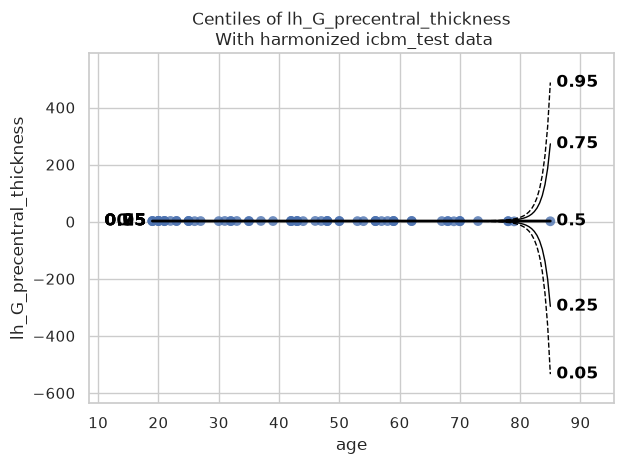

In [6]:
own_template = BLR(
    name="own",
    heteroskedastic=True,
    fixed_effect=True,
    warp_name="WarpSinhArcsinh",
    basis_function_mean=BsplineBasisFunction(basis_column=0, nknots=5, degree=3),
    basis_function_var=BsplineBasisFunction(basis_column=0, nknots=5, degree=3),
)
own_model = NormativeModel(
    template_regression_model=own_template,
    inscaler="standardize", outscaler="standardize",
    savemodel=False, saveresults=False, saveplots=False, evaluate_model=True,
    save_dir="results/own",
)
own_test = own_model.fit_predict(adaptation, copy.deepcopy(test))
plot_centiles_advanced(own_model, scatter_data=own_test, show_legend=False);

## 7. Option 2: transfer the 67K model

Transfer keeps the age curve the big model learned from 67,000 people and only learns, from your controls, how much your site is shifted and how wide it scatters.

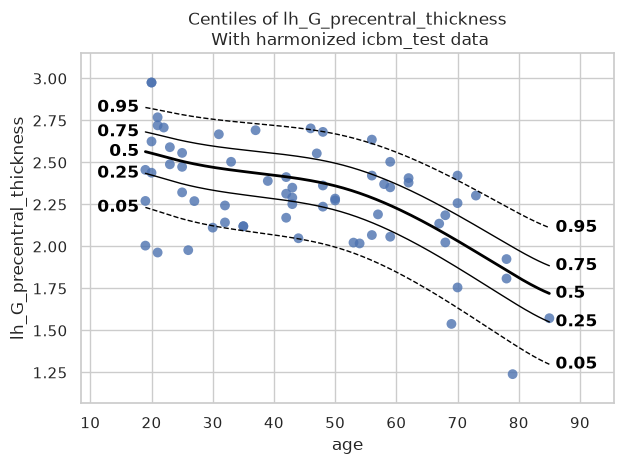

In [7]:
tr_test = copy.deepcopy(test)
transferred_model = big_model.transfer_predict(adaptation, tr_test, save_dir="results/transfer")
plot_centiles_advanced(transferred_model, scatter_data=tr_test, show_legend=False);

## 8. Compare on the people neither model has seen

Two checks of the Z-score **distribution** of healthy people:

- **outside |Z| > 2**: should be about 5%.
- **MACE** (mean absolute centile error): for the 5th, 25th, 50th, 75th and 95th centile, how far the share of people below that centile is from what it should be. 0 is perfect.

In [8]:
def scores(data):
    z = data.Z.sel(response_vars=REGION).values
    return {
        "outside |Z|>2 (%)": round(float(np.mean(np.abs(z) > 2) * 100), 1),
        "MACE": round(float(data.statistics.sel(response_vars=REGION, statistic="MACE")), 3),
    }

pd.DataFrame({"fit on my site only": scores(own_test), "67K transfer": scores(tr_test)})

,fit on my site only,67K transfer
outside |Z|>2 (%),24.600,10.800
MACE,0.077,0.048


## 9. Your turn

- Change `splits` in section 5, e.g. `(0.12, 0.88)` for 10 controls or `(0.71, 0.29)` for 60, and run everything from there again. When does transfer matter most?
- Change `random_state` to get a different set of controls. Which model changes more? (The web app's draw 1 is `random_state=5`; draws 2–50 are `random_state` 0–49, skipping 5.)
- Change `REGION` to another thickness column, e.g. `rh_G_precentral_thickness`.

The [web app](https://predictive-clinical-neuroscience.github.io/PCNtoolkit-demo-transfer/) shows all of these, precomputed.

**Your own data:** replace `icbm` with your table (same column names as the model; sex coded `F`/`M` if you model it), keep healthy controls for transfer, and score everyone else, including patients. No Python? [PCNportal](https://pcnportal.dccn.nl/) does the same transfer in the browser.

## 10. Next step: add sex back

So far both models ignore sex. In ICBM, women's precentral cortex is thicker than men's, so a model without sex should give healthy women Z-scores that are too high and healthy men Z-scores that are too low. The two scores above can't see this: they pool everyone, and a sex difference just looks like a bit more spread.

Below we fit both models again on **the same people**, now with sex as a second batch effect, and compare the mean Z of women and men in the test set. For healthy people, both should be close to 0, and the gap between them should be close to 0.

In [9]:
ad_ids = adaptation.subject_ids.values.astype(str)
adaptation_sex = to_normdata(icbm[icbm.sub_id.isin(ad_ids)], "adaptation_sex", ("site", "sex"))
test_sex = to_normdata(icbm[~icbm.sub_id.isin(ad_ids)], "test_sex", ("site", "sex"))

own_model_sex = NormativeModel(
    template_regression_model=own_template,
    inscaler="standardize", outscaler="standardize",
    savemodel=False, saveresults=False, saveplots=False, evaluate_model=True,
    save_dir="results/own_sex",
)
own_test_sex = own_model_sex.fit_predict(adaptation_sex, copy.deepcopy(test_sex))
tr_test_sex = copy.deepcopy(test_sex)
big_model.transfer_predict(adaptation_sex, tr_test_sex, save_dir="results/transfer_sex")

sex_of = icbm.set_index("sub_id")["sex"]

def mean_z_by_sex(data):
    z = pd.Series(data.Z.sel(response_vars=REGION).values, index=data.subject_ids.values.astype(str))
    out = z.groupby(sex_of.loc[z.index].values).mean().round(2)
    out["gap (women - men)"] = round(out["F"] - out["M"], 2)
    out["outside |Z|>2 (%)"] = round(float(np.mean(np.abs(z) > 2) * 100), 1)
    return out

pd.DataFrame({
    "my site only, no sex": mean_z_by_sex(own_test),
    "my site only, with sex": mean_z_by_sex(own_test_sex),
    "67K transfer, no sex": mean_z_by_sex(tr_test),
    "67K transfer, with sex": mean_z_by_sex(tr_test_sex),
}).rename(index={"F": "mean Z, women", "M": "mean Z, men"})

,"my site only, no sex","my site only, with sex","67K transfer, no sex","67K transfer, with sex"
"mean Z, women",0.08,-0.15,0.14,-0.27
"mean Z, men",-0.71,-0.46,-0.47,-0.16
gap (women - men),0.79,0.31,0.61,-0.11
outside |Z|>2 (%),24.60,21.50,10.80,20.00


With sex in the model, the gap between women and men shrinks: the sex bias is mostly gone. The price: transfer now learns a shift and a spread for women and men separately, from about 10 people each, so its Z-scores get noisier and more people end up outside |Z| > 2. Bias or noise: with few controls you have to choose. Try other `splits` in section 5: how many controls do you need before modelling sex is the better deal?

Questions: [NeuroStars, tag pcntoolkit](https://neurostars.org/tag/pcntoolkit) · [GitHub issues](https://github.com/predictive-clinical-neuroscience/PCNtoolkit/issues)